In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [8]:
data = pd.read_csv("CIFAR10/cifar-10.csv")

X = data.drop('label', axis=1).values
y = data['label'].values

X = X.astype('float32') / 255.0

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
model = keras.Sequential([
    layers.Input(shape=(3072,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [10]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=10,
                    validation_data=(x_test, y_test))

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.3111 - loss: 1.8926 - val_accuracy: 0.3768 - val_loss: 1.7383
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.3821 - loss: 1.7188 - val_accuracy: 0.3771 - val_loss: 1.7396
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.4038 - loss: 1.6598 - val_accuracy: 0.3983 - val_loss: 1.6517
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.4268 - loss: 1.6092 - val_accuracy: 0.4090 - val_loss: 1.6182
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.4390 - loss: 1.5791 - val_accuracy: 0.4338 - val_loss: 1.5784
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.4484 - loss: 1.5464 - val_accuracy: 0.4194 - val_loss: 1.6225
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.4545 - loss: 1.5230 - val_accuracy: 0.4213 - val_loss: 1.6308
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.4661 - loss: 

In [11]:
model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4338 - loss: 1.5643


[1.5642924308776855, 0.43380001187324524]

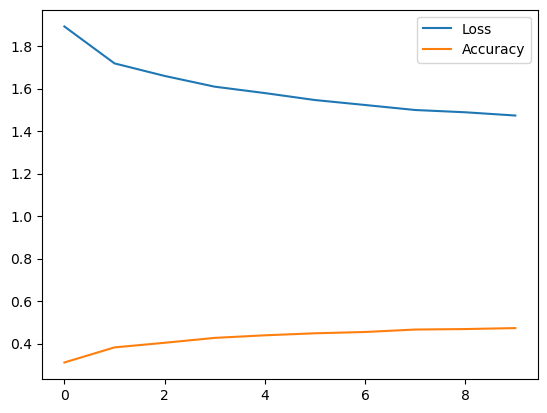

In [12]:
plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['accuracy'], label='Accuracy')
plt.legend()
plt.show()